In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/mean log2(TPM+1) of 52 EGA Models vs mean log2(TPM+1) of 1,667 Not EGA Models.csv")


df = df.rename(columns={
    "mean log2(TPM+1) of 52 GEJA Models Expression (Short-read) Public 26Q1": "GEJA",
    "mean log2(TPM+1) of 1,667 Not GEJA Models Expression (Short-read) Public 26Q1": "Not_GEJA"
})

In [14]:
import sys
import pandas as pd
import numpy as np
import matplotlib

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0


In [15]:
##Please disregard all instances of "GEJA." "GEJA" has been generalized into "EGA" through the data for the final output of this project.

df["distance_to_yx"] = (df["GEJA"] - df["Not_GEJA"]) / np.sqrt(2)
ranked_genes = df.sort_values(
    by="distance_to_yx", ascending=False
).reset_index(drop=True)

target_genes = ["KRT19", "PLBD1", "GPRC5A", "IFITM3", "CD59", "TUBB", "ACTB", "GAPDH"]

print("--- Outlier & Reference Gene Statistics ---")
for gene in target_genes:
  gene_row = ranked_genes[ranked_genes["Gene"] == gene]
  if not gene_row.empty:
    g_index = ranked_genes.index[ranked_genes["Gene"] == gene].tolist()[0] + 1
    g_dist = gene_row["distance_to_yx"].values[0]
    g_ega = gene_row["GEJA"].values[0]
    g_non = gene_row["Not_GEJA"].values[0]
    print(
        f"Gene: {gene:<6} | Rank: {g_index:<5} | Distance: {g_dist:.2f}"
        f" log2-units | EGA: {g_ega:.2f} | Non-EGA: {g_non:.2f}"
    )
print("-------------------------------------------")

--- Outlier & Reference Gene Statistics ---
Gene: KRT19  | Rank: 1     | Distance: 2.85 log2-units | EGA: 8.60 | Non-EGA: 4.57
Gene: PLBD1  | Rank: 11    | Distance: 1.90 log2-units | EGA: 4.78 | Non-EGA: 2.10
Gene: GPRC5A | Rank: 42    | Distance: 1.48 log2-units | EGA: 6.22 | Non-EGA: 4.12
Gene: IFITM3 | Rank: 446   | Distance: 0.74 log2-units | EGA: 8.49 | Non-EGA: 7.44
Gene: CD59   | Rank: 2219  | Distance: 0.26 log2-units | EGA: 8.30 | Non-EGA: 7.94
Gene: TUBB   | Rank: 17366 | Distance: -0.24 log2-units | EGA: 9.27 | Non-EGA: 9.60
Gene: ACTB   | Rank: 14483 | Distance: -0.07 log2-units | EGA: 11.20 | Non-EGA: 11.30
Gene: GAPDH  | Rank: 15165 | Distance: -0.09 log2-units | EGA: 11.75 | Non-EGA: 11.88
-------------------------------------------


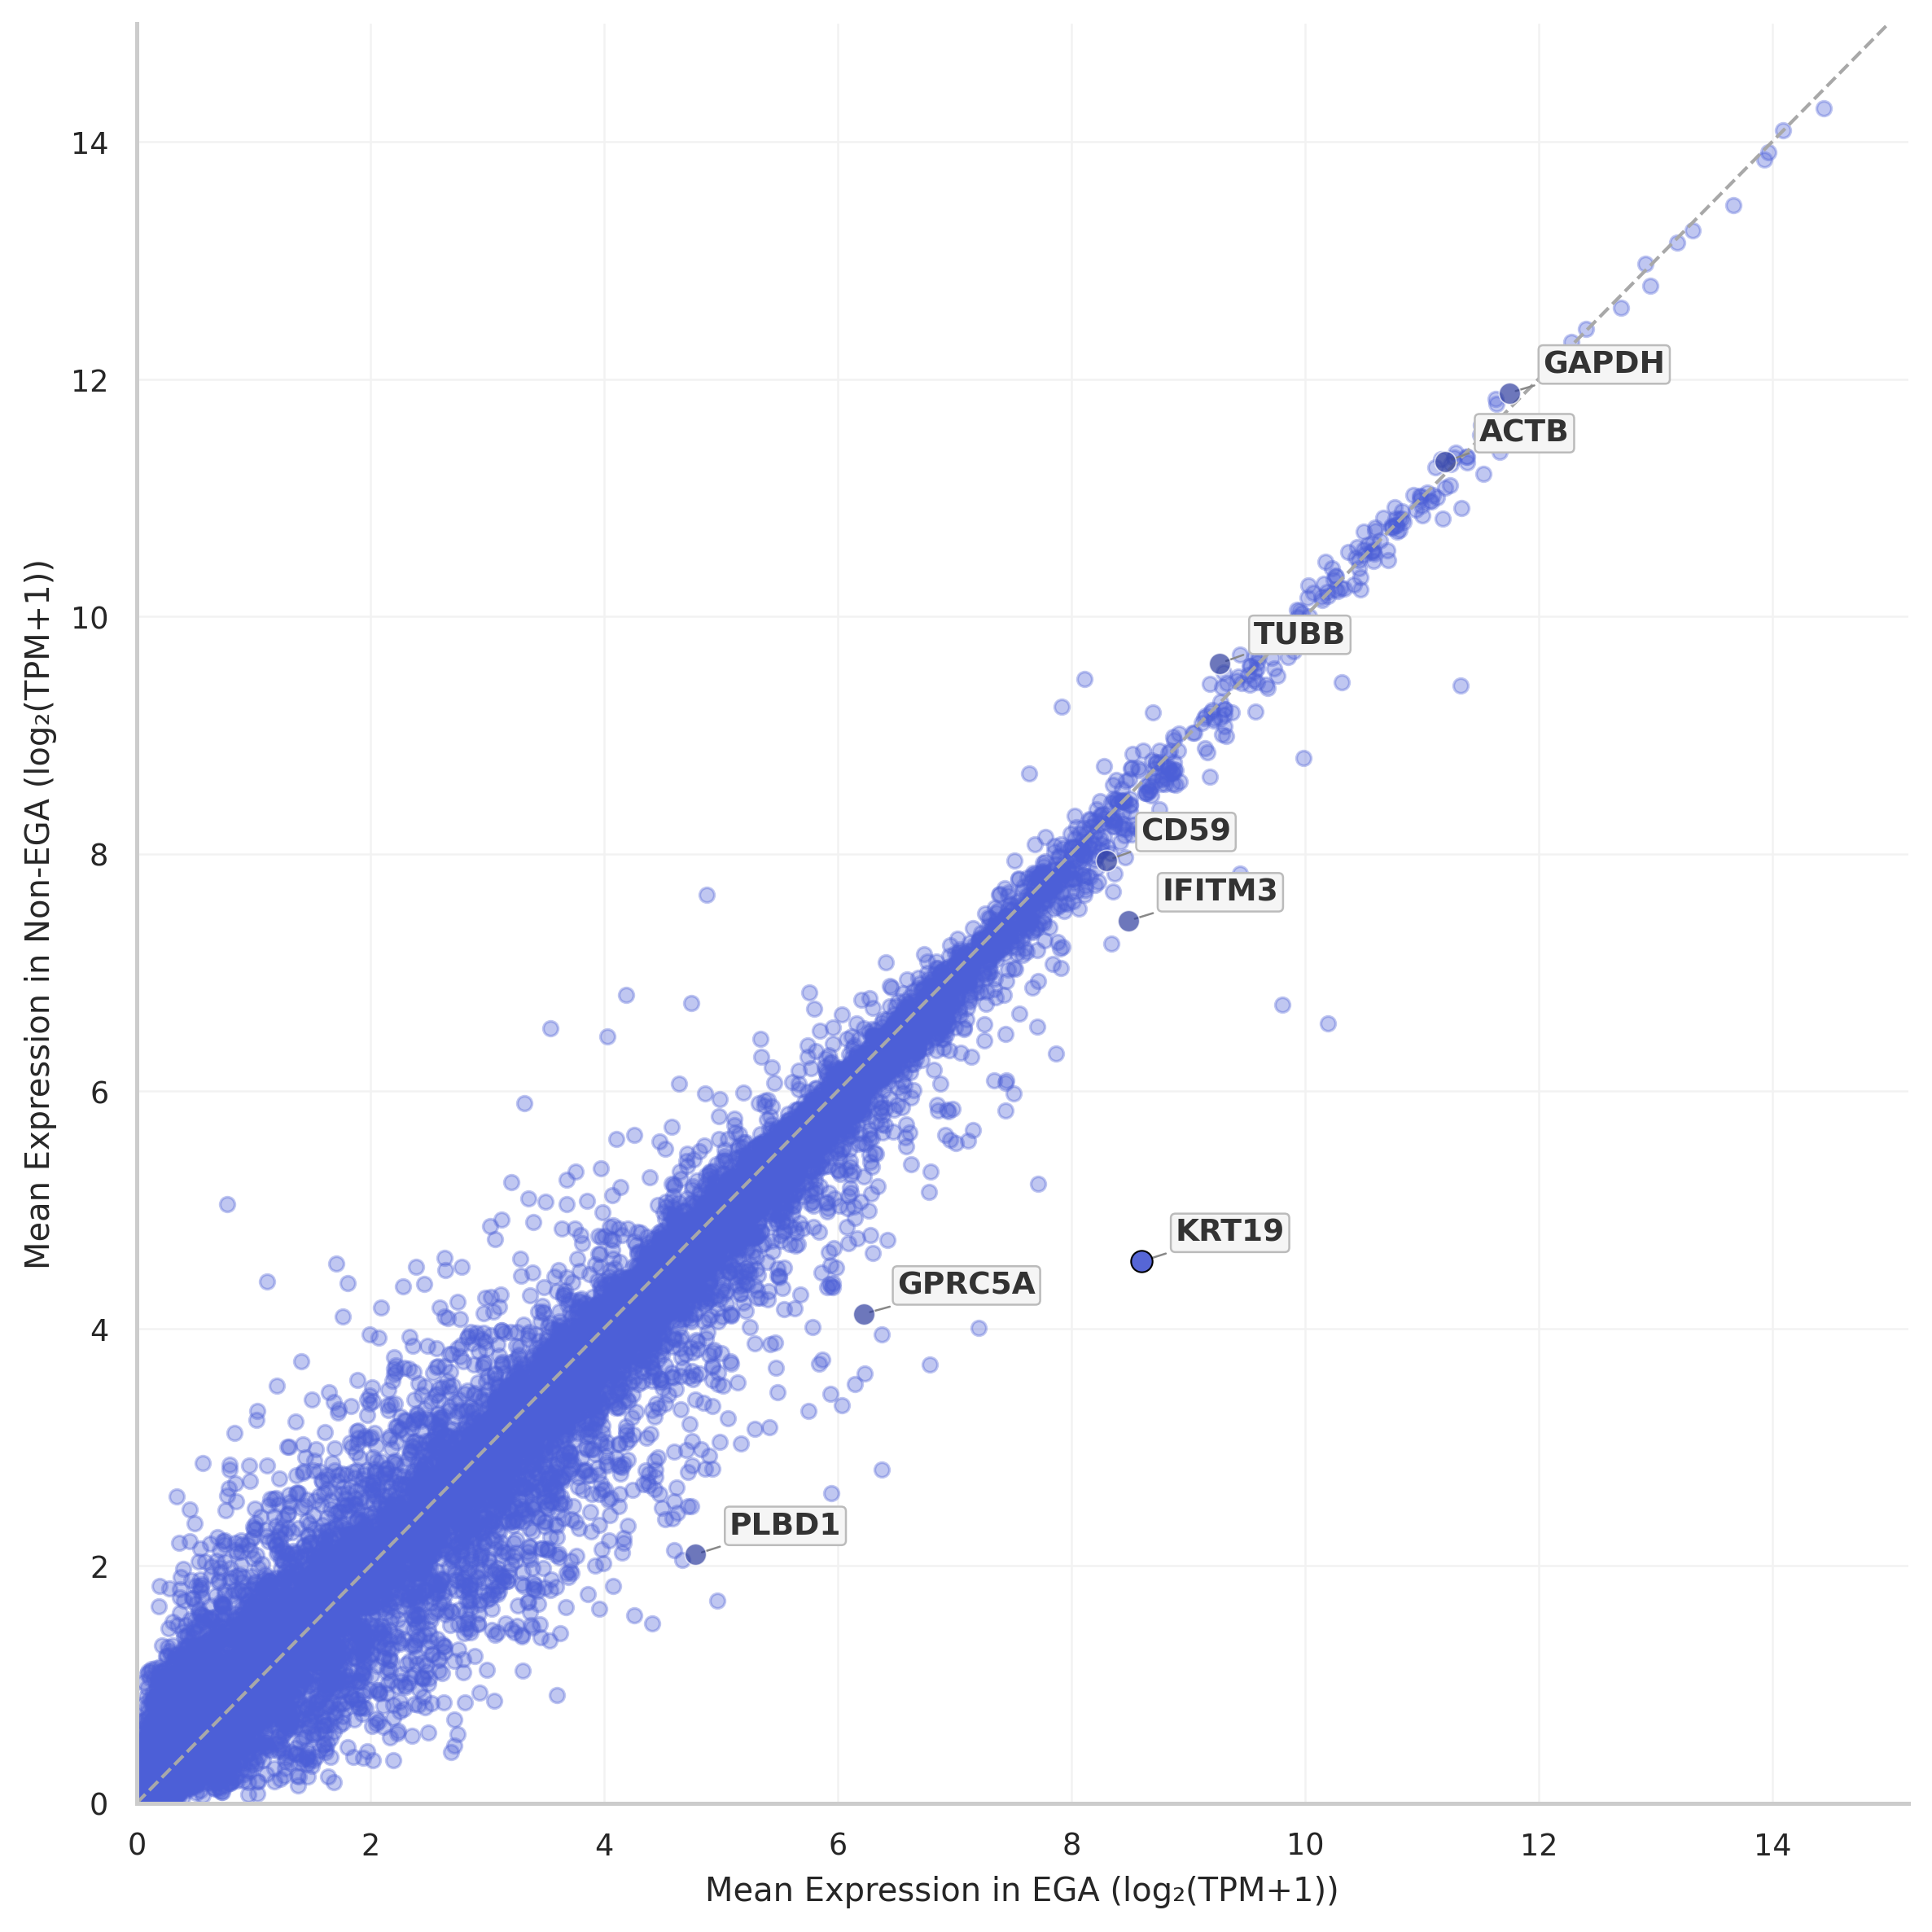

In [16]:
import matplotlib.pyplot as plt

import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="paper"
)

highlight_genes = ["PLBD1", "GPRC5A", "IFITM3", "CD59", "TUBB", "ACTB", "GAPDH"]

plt.figure(figsize=(8,8), dpi=300)

# Find KRT19

highlight = df[df["Gene"].isin(highlight_genes)]
others = df[~df["Gene"].isin(highlight_genes)]
krt = df[df["Gene"] == "KRT19"]


plt.scatter(
    others["GEJA"],
    others["Not_GEJA"],
    s=75,
    color="#4C5FD7",
    alpha=0.35,
    rasterized=True,
    marker="."
)

plt.scatter(
    highlight["GEJA"],
    highlight["Not_GEJA"],
    s=40,
    color="#2F3E9E",
    alpha=0.7,
    edgecolors="white",
    linewidths=0.4,
    zorder=4
)

plt.scatter(
    krt["GEJA"],
    krt["Not_GEJA"],
    s=40,
    color="#5666D6",
    edgecolors="black",
    linewidths=0.5,
    zorder=5,
    rasterized=True,
)

# Add label
plt.annotate(
    "KRT19",
    xy=(krt["GEJA"].iloc[0], krt["Not_GEJA"].iloc[0]),
    xytext=(10, 6),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color="#333333",
    arrowprops=dict(
        arrowstyle="-",
        color="#888888",
        lw=0.6
    ),
    bbox=dict(
      boxstyle="round,pad=0.15",
      fc="#F5F5F5",
      ec="#BBBBBB",
      lw=0.6
  )
)

for _, row in highlight.iterrows():
    plt.annotate(
        row["Gene"],
        xy=(row["GEJA"], row["Not_GEJA"]),
        xytext=(10, 6),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#333333",
        arrowprops=dict(
            arrowstyle="-",
            color="#888888",
            lw=0.6
        ),
        bbox=dict(
          boxstyle="round,pad=0.15",
          fc="#F5F5F5",
          ec="#BBBBBB",
          lw=0.6
      )
    )

plt.xlabel("Mean Expression in EGA (log₂(TPM+1))")
plt.ylabel("Mean Expression in Non-EGA (log₂(TPM+1))")

plt.plot(
    [0,15],
    [0,15],
    color="#A8A8A8",
    linestyle="--",
    linewidth=1
)

ax = plt.gca()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.grid(
    color="#F2F2F2",
    linewidth=0.6
)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

plt.xlim(0, df["GEJA"].max() * 1.05)
plt.ylim(0, df["Not_GEJA"].max() * 1.05)

plt.tight_layout()

plt.savefig("Figure4.pdf", bbox_inches="tight")
plt.savefig("Figure4.png", dpi=600, bbox_inches="tight")

plt.show()
ax.margins(x=0, y=0)

In [17]:
plt.savefig(
    "Figure2.pdf",
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>